# CNN Training Using a Custom Dataset
![](https://drive.google.com/uc?id=1n1ad5alG5W1wdLk1NusbEV-m_jlHDVKL)

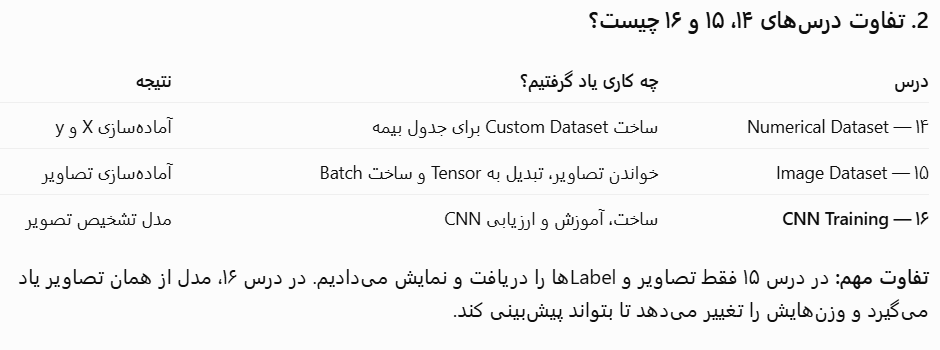

In [1]:
import torch
import os
from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

In [2]:
!unzip '/content/Classification_dataset_v3.zip'

'unzip' is not recognized as an internal or external command,
operable program or batch file.


In [3]:
import zipfile

with zipfile.ZipFile("Classification_dataset_v3.zip", "r") as zip_ref:
    zip_ref.extractall(".")

In [5]:
import os

image_dir = 'Classification_dataset_v3/images/train'

for label, class_dir in enumerate(sorted(os.listdir(image_dir))):
    print(label, class_dir)

0 Cat
1 Dog
2 person


In [ ]:
# Custom Dataset: Read images and their labels from class folders
class ImageDataset(Dataset):

    # Initialize dataset and collect image paths and labels
    def __init__(self, image_dir, transform=None):
        self.image_dir = image_dir
        self.image_paths = []  # Store paths of all images
        self.labels = []       # Store numeric labels (0, 1, 2)
        self.class_name = {}   # Map labels to names (e.g., 0 -> Cat)
        self.transform = transform  # Optional image preprocessing

        # Loop through class folders (Cat, Dog, person)
        for label, class_dir in enumerate(os.listdir(image_dir)):
            self.class_name[label] = class_dir
            class_path = os.path.join(image_dir, class_dir)

            # Collect each image path and its corresponding label
            for img_name in os.listdir(class_path):
                self.image_paths.append(os.path.join(class_path, img_name))
                self.labels.append(label)

    # Return total number of images in the dataset
    def __len__(self):
        return len(self.image_paths)

    # Load one image and its label using an index
    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert("RGB")  # Read as RGB
        label = self.labels[idx]  # Get corresponding label

        if self.transform:
            image = self.transform(image)  # Apply Resize, ToTensor, Normalize

        return image, label  # Return one image and its label

In [7]:
transform = transforms.Compose([
    transforms.Resize((128,128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])]
)
# mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]

In [9]:
# Paths to training and testing images
train_image_dir = 'Classification_dataset_v3/images/train'
test_image_dir = 'Classification_dataset_v3/images/test'

# Create custom datasets
train_image_dataset = ImageDataset(image_dir=train_image_dir, transform=transform)
test_image_dataset = ImageDataset( image_dir=test_image_dir,transform=transform)

print("Training images:", len(train_image_dataset))
print("Testing images:", len(test_image_dataset))

Training images: 3018
Testing images: 200


In [ ]:
# DataLoader: Group dataset images and labels into batches of 32
# shuffle=True randomly changes the image order in each epoch
train_image_loader = DataLoader(dataset=train_image_dataset, batch_size=32, shuffle=True)
test_image_loader = DataLoader(dataset=test_image_dataset, batch_size=32, shuffle=True)

In [11]:
for images,labels in train_image_loader:
  print(images.shape, labels.shape)
  break

torch.Size([32, 3, 128, 128]) torch.Size([32])


In [12]:
import matplotlib.pyplot as plt
import numpy as np

In [13]:
print(train_image_dataset.class_name)
print(test_image_dataset.class_name)

{0: 'Cat', 1: 'Dog', 2: 'person'}
{0: 'Cat', 1: 'Dog', 2: 'person'}


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.99215686..1.0].


torch.Size([32, 3, 128, 128]) torch.Size([32])
(3, 128, 128)
Dog
(128, 128, 3)
1


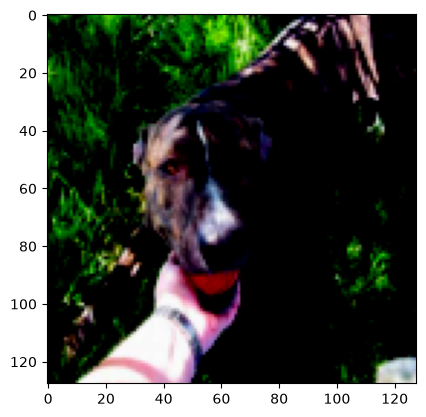

In [14]:
for images, labels in train_image_loader:
  print(images.shape, labels.shape)
  img = images[0].numpy()
  print(img.shape)
  label = labels[0].item()
  print(train_image_dataset.class_name[label])
  img = np.transpose(img, (1,2,0))
  print(img.shape)
  print(label)
  plt.imshow(img)
  break

# Custom CNN Architecture

In [15]:
import torch.nn as nn
import torch.optim as optim

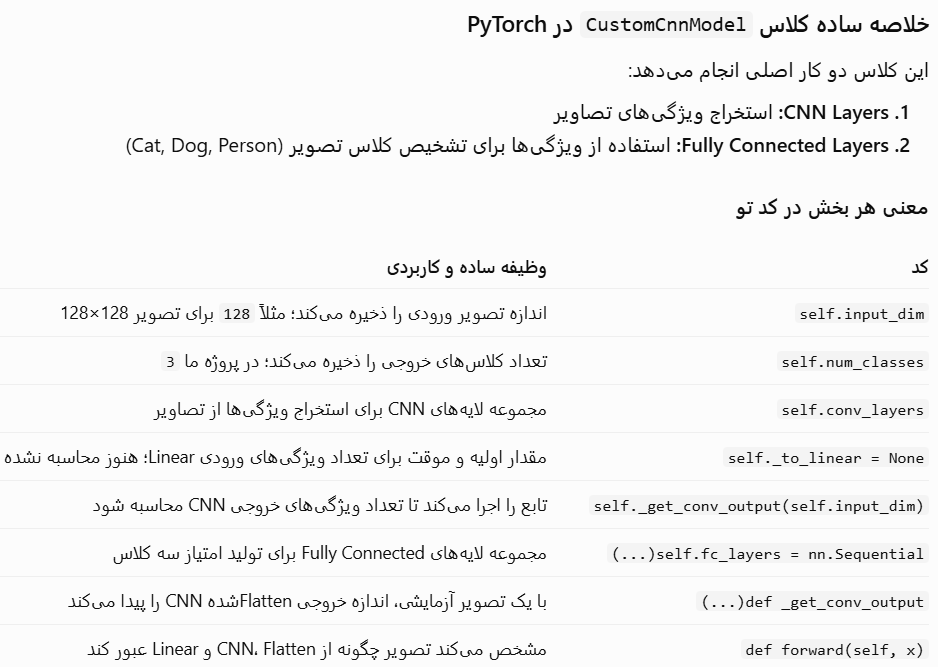

In [ ]:
class CustomCnnModel(nn.Module):
  def __init__(self,input_dim, num_classes):
    super(CustomCnnModel, self).__init__()
    self.input_dim = input_dim
    self.num_classes = num_classes

    # Extract image features
    self.conv_layers = nn.Sequential(
        # C1
        
        # Apply 32 learnable filters to RGB input (3 -> 32 channels)
        nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1),
        # 128x128x3 --> 3x3x3x32 --> wxhx32
        # Normalize each feature channel for more stable training
        nn.BatchNorm2d(32),
        nn.ReLU(),
        # Keep the maximum value in each 2x2 region (128 -> 64)
        # Keep strong local features while reducing spatial size
        nn.MaxPool2d(kernel_size=2, stride=2),

        # C2
        nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),

        # C3
        nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(128),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),

        # C4
        nn.Conv2d(128, 256, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(256),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2)
    )

    self._to_linear = None  # Placeholder for flattened feature size
    self._get_conv_output(self.input_dim)  # Automatically calculate the flattened CNN output size

    # Convert features into class scores
    self.fc_layers = nn.Sequential(
        nn.Linear(self._to_linear, 512),
        nn.ReLU(),
        # nn.Dropout(0.2)
        nn.Linear(512, 128),
        nn.ReLU(),
        nn.Linear(128, self.num_classes),
    )

    # 256 x 12 x 12

  # Finds the size of the flattened CNN output with a test image
  def _get_conv_output(self, input_dim=128):
    with torch.no_grad():
      dummy_input = torch.zeros(1,3, input_dim, input_dim)
      output = self.conv_layers(dummy_input)
      self._to_linear = output.view(1, -1).size(1)

  # Define how real images pass through CNN -> Flatten -> Linear (ANN)
  def forward(self,x):
    x = self.conv_layers(x)
    x = x.view(x.size(0), -1)
    x = self.fc_layers(x)
    return x

In [18]:
# Initialize Model
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = CustomCnnModel(input_dim=128, num_classes=3).to(device)

In [19]:
print(model)

CustomCnnModel(
  (conv_layers): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_sta

In [20]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(),lr=0.001)

In [21]:
# 100 epoch

# 1000
# 10 batch size
# 100

# 1 epoch --> 100 iteration
# 2 epoch --> 100 iteration

In [22]:
len(train_image_loader)

95

In [23]:
# Training loop
epochs = 40
for epoch in range(epochs):
  model.train()
  running_loss = 0.0
  for images, labels in train_image_loader:
    images,labels = images.to(device), labels.to(device)
    optimizer.zero_grad()  # Clear gradients from previous iteration
    outputs = model(images) # Predict class scores for the batch
    # [x, 3, 128, 128]

    loss = criterion(outputs, labels) # Calculate prediction error
    loss.backward() # Calculate gradients using backpropagation
    optimizer.step() # Update model weights
    running_loss+=loss.item() 
  print(f"Epoch {epoch+1}/{epochs}, Loss : {running_loss/len(train_image_loader)}")


Epoch 1/40, Loss : 0.9874985249418962
Epoch 2/40, Loss : 0.6036485301820855
Epoch 3/40, Loss : 0.5417597435022655
Epoch 4/40, Loss : 0.48106101814069246
Epoch 5/40, Loss : 0.41899972448223516
Epoch 6/40, Loss : 0.3780418679902428
Epoch 7/40, Loss : 0.33994550767697784
Epoch 8/40, Loss : 0.29613816377363705
Epoch 9/40, Loss : 0.26180646145030073
Epoch 10/40, Loss : 0.21448124404016294
Epoch 11/40, Loss : 0.2356820018667924
Epoch 12/40, Loss : 0.16742512344529753
Epoch 13/40, Loss : 0.13960911872747697
Epoch 14/40, Loss : 0.11747297179934225
Epoch 15/40, Loss : 0.09335549426706213
Epoch 16/40, Loss : 0.051353823924192084
Epoch 17/40, Loss : 0.06521725357068997
Epoch 18/40, Loss : 0.03775037614702198
Epoch 19/40, Loss : 0.0830482180205811
Epoch 20/40, Loss : 0.0403118230819114
Epoch 21/40, Loss : 0.061479951717621203
Epoch 22/40, Loss : 0.06846696644237167
Epoch 23/40, Loss : 0.04574222237983792
Epoch 24/40, Loss : 0.028876898967121777
Epoch 25/40, Loss : 0.010906976349284185
Epoch 26/40,

In [24]:
# Save trained model weights for later use
torch.save(model.state_dict(), "cnn_model.pth")

In [ ]:
# # Check the number of labels in the first test batch (32 labels)
for images, labels in test_image_loader:
  print(labels.shape)
  break

torch.Size([32])


In [26]:
# Evaluate model

model.eval() # Switch to evaluation mode
correct = 0
total = 0

with torch.no_grad():  # Disable gradient tracking
  for images, labels in test_image_loader:
    images,labels = images.to(device), labels.to(device)
    outputs = model(images)
    _, predicted = torch.max(outputs, 1)
    total += labels.size(0)
    correct += (predicted == labels).sum().item()

print(f"Test accuracy is :{100* correct / total:.2f}%")


Test accuracy is :84.50%


CustomCnnModel: 
Building a CNN architecture and defining how images pass through the network
ImageClassifier: 
Loading a trained CNN and using it to predict new images

In [ ]:
# CNN recognizes the image, but OpenCV writes the result to the image and stores it
import cv2

In [ ]:
# Load the trained model for inference / Loads the trained model and uses it on new images
class ImageClassifier:

  # Load trained CNN and prepare image preprocessing
  def __init__(self, model_path, class_names):
     # Select GPU if available, otherwise CPU
    self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    # Recreate the same CNN architecture used during training
    self.model = CustomCnnModel(input_dim=128, num_classes=3).to(self.device)
    # Load previously learned CNN weights from the .pth file
    self.model.load_state_dict(torch.load(model_path, map_location=self.device))
    # Switch model to inference mode (no training)
    self.model.eval()
    # Store class names: {0: 'Cat', 1: 'Dog', 2: 'person'}
    self.class_names = class_names
     # Apply the same image preprocessing used during training
    self.transform = transforms.Compose([
      transforms.Resize((128,128)),
      transforms.ToTensor(),
      transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])]
    )

  # This function is the main part of Inference
  def predict(self, image_path):
    # 1. Read a new image and convert it to RGB
    image = Image.open(image_path).convert("RGB")
    # 2. Resize, normalize, and add batch dimension
    input_tensor = self.transform(image).unsqueeze(0).to(self.device)
    # 3. Predict using the trained CNN (without gradients)
    with torch.no_grad():
      output = self.model(input_tensor)
      # 4. Select the class with the highest score
      _, predicted = torch.max(output, 1)
    # 5. Convert predicted class index to class name
    label = self.class_names[predicted.item()]

    # 6. Read original image using OpenCV
    img = cv2.imread(image_path)
    
    # 7. Write predicted class name on the original image
    cv2.putText(img, label, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 0, 0), 2)
    # 8. Save the annotated image
    cv2.imwrite("output_image.jpg",img)
    return label



In [ ]:
# Load the trained CNN model
classifier = ImageClassifier("cnn_model.pth", train_image_dataset.class_name)

# Path to a test image

# image_path = "Classification_dataset_v3/images/test/Dog/dog_1000.jpg"
# image_path = "Classification_dataset_v3/images/test/Cat/cat_1026.jpg"
image_path = "Classification_dataset_v3/images/test/person/person_2030.jpg"

# Predict the image class
label = classifier.predict(image_path)

print(f"Predicted class is: {label}")

Predicted class is: person


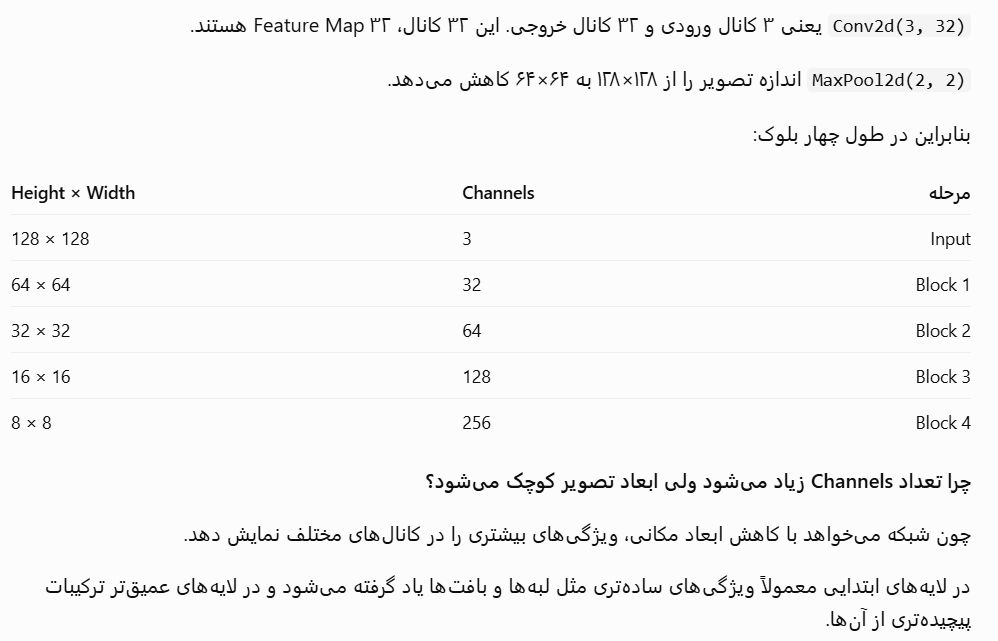